# Crypto Lab 08 — Elliptic Curve Cryptography

**CYBR 3570: Applied Cryptography**  
**Topic:** Elliptic curves, finite fields, ECDLP, ECDH, ECDSA risks, and curve validation

## Today's big question

> Why does ECC give us strong public-key cryptography with much smaller keys, and what can go wrong if we use it incorrectly?

This notebook is an educational exploration. We will use small toy curves so the math is visible. These examples are **not secure** and should never be used for real cryptography.

## Learning Objectives

By the end of this notebook, you should be able to:

1. Explain why ECC works over finite fields.
2. Identify points on a toy elliptic curve.
3. Implement point addition and scalar multiplication for a small curve.
4. Explain the elliptic curve discrete logarithm problem.
5. Demonstrate a toy ECDH exchange.
6. Explain why ECDSA nonce reuse is dangerous.
7. Explain why validating curve points matters.
8. Connect ECC design choices to secure engineering practices.

## Setup

In [1]:
import math
from dataclasses import dataclass
from typing import Optional, List, Tuple
import matplotlib.pyplot as plt

print("Elliptic curve lab setup complete")

Elliptic curve lab setup complete


## Part 1 — Elliptic curves over the real numbers

The chapter begins with elliptic curves drawn over the real numbers. A common form is:

$$y^2 = x^3 + ax + b$$

For example, the chapter uses a curve similar to:

$$y^2 = x^3 - 4x$$

Over the real numbers, this looks like a smooth curve. In cryptography, however, we use finite fields, so the picture changes dramatically.

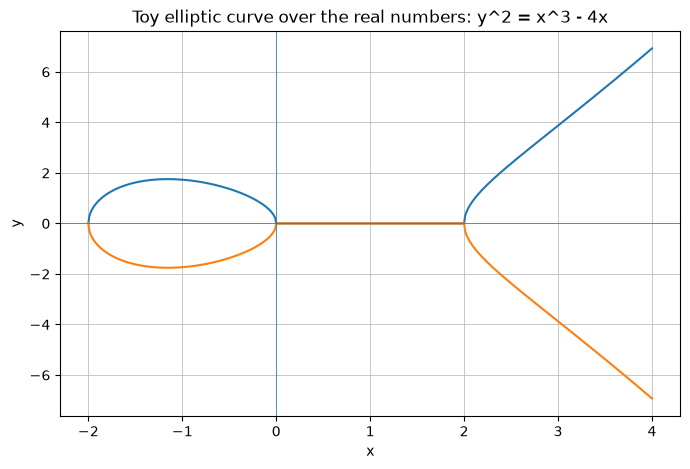

In [2]:
# Plot y^2 = x^3 - 4x over the real numbers.

xs = [x / 100 for x in range(-300, 401)]
upper_x, upper_y, lower_x, lower_y = [], [], [], []
for x in xs:
    rhs = x**3 - 4*x
    if rhs >= 0:
        y = math.sqrt(rhs)
        upper_x.append(x)
        upper_y.append(y)
        lower_x.append(x)
        lower_y.append(-y)

plt.figure(figsize=(8, 5))
plt.plot(upper_x, upper_y)
plt.plot(lower_x, lower_y)
plt.axhline(0, linewidth=0.5)
plt.axvline(0, linewidth=0.5)
plt.title("Toy elliptic curve over the real numbers: y^2 = x^3 - 4x")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, linewidth=0.5)
plt.show()

### Exercise 1

In your own words, explain why the curve is symmetric across the x-axis.

#### Answer: 
- Becasue it is a y^2 it gives a positive and negative value so there is symmetry over the positive and the negative. 


## Part 2 — Elliptic curves over finite fields

Cryptographic elliptic curves are usually defined over a finite field such as integers modulo a prime number `p`.

For a toy curve:

$$y^2 \equiv x^3 + ax + b \pmod p$$

A point `(x, y)` belongs to the curve only if it satisfies the equation modulo `p`.

Number of affine points: 99
First 10 points: [(0, 10), (0, 87), (1, 43), (1, 54), (3, 6), (3, 91), (4, 47), (4, 50), (10, 21), (10, 76)]


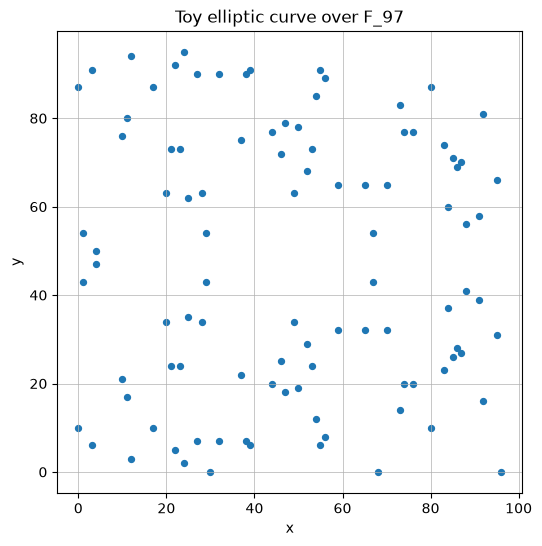

In [3]:
def curve_points(a: int, b: int, p: int) -> List[Tuple[int, int]]:
    """Return all affine points on y^2 = x^3 + ax + b mod p."""
    points = []
    for x in range(p):
        rhs = (x**3 + a*x + b) % p
        for y in range(p):
            if (y*y) % p == rhs:
                points.append((x, y))
    return points

# A small educational curve: y^2 = x^3 + 2x + 3 over F_97
a, b, p = 2, 3, 97
points = curve_points(a, b, p)
print(f"Number of affine points: {len(points)}")
print(f"First 10 points: {points[:10]}")

plt.figure(figsize=(6, 6))
plt.scatter([x for x, y in points], [y for x, y in points], s=18)
plt.title("Toy elliptic curve over F_97")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, linewidth=0.5)
plt.show()

### Exercise 2

Why does the finite-field version look like a cloud of points instead of a smooth curve?

#### Answer
- Becasue every x has 2 y points so it is scattered and cloud like. It is also a discrete function and the y range is positive. 

## Part 3 — Point representation and validation

We will represent the point at infinity with `None`. The point at infinity acts like zero for elliptic curve point addition.

Before using a point, we should validate that it is actually on the curve.

In [4]:
Point = Optional[Tuple[int, int]]

@dataclass(frozen=True)
class Curve:
    a: int
    b: int
    p: int

    def contains(self, P: Point) -> bool:
        if P is None:
            return True
        x, y = P
        return (y*y - (x**3 + self.a*x + self.b)) % self.p == 0

curve = Curve(a=2, b=3, p=97)

for P in [(3, 6), (3, 91), (10, 20), None]:
    print(f"{P} on curve? {curve.contains(P)}")

(3, 6) on curve? True
(3, 91) on curve? True
(10, 20) on curve? False
None on curve? True


### Exercise 3

Find five valid points and five invalid points on the toy curve. Use the `curve.contains()` method.

In [10]:
# TODO: Fill in your own examples.
valid_examples = [(0, 87), (4, 47), (3, 6), (3, 91), (65, 65)]
invalid_examples = [(0, 0), (1, 1), (2, 81), (3, 67), (67, 4)]

for P in valid_examples:
    print(P, curve.contains(P))
for P in invalid_examples:
    print(P, curve.contains(P))

(0, 87) True
(4, 47) True
(3, 6) True
(3, 91) True
(65, 65) True
(0, 0) False
(1, 1) False
(2, 81) False
(3, 67) False
(67, 4) False


## Part 4 — Modular inverses and point addition

Point addition uses division, but in a finite field division means multiplication by a modular inverse.

For example:

$$
rac{a}{b} \pmod p = a \cdot b^{-1} \pmod p$$

Python's built-in `pow(value, -1, p)` computes a modular inverse when it exists.

In [11]:
def inv_mod(x: int, p: int) -> int:
    """Return x^{-1} modulo p."""
    return pow(x % p, -1, p)

for x in [2, 3, 5, 10]:
    print(f"{x} inverse mod 97 = {inv_mod(x, 97)}; check: {(x * inv_mod(x, 97)) % 97}")

2 inverse mod 97 = 49; check: 1
3 inverse mod 97 = 65; check: 1
5 inverse mod 97 = 39; check: 1
10 inverse mod 97 = 68; check: 1


In [12]:
def point_neg(P: Point, curve: Curve) -> Point:
    if P is None:
        return None
    x, y = P
    return (x, (-y) % curve.p)


def point_add(P: Point, Q: Point, curve: Curve) -> Point:
    """Add two points on a short Weierstrass curve over F_p."""
    if P is None:
        return Q
    if Q is None:
        return P

    x1, y1 = P
    x2, y2 = Q
    p = curve.p

    if x1 == x2 and (y1 + y2) % p == 0:
        return None

    if P == Q:
        # Point doubling slope: m = (3x^2 + a) / (2y)
        m = ((3 * x1 * x1 + curve.a) * inv_mod(2 * y1, p)) % p
    else:
        # Distinct point slope: m = (y2 - y1) / (x2 - x1)
        m = ((y2 - y1) * inv_mod(x2 - x1, p)) % p

    x3 = (m*m - x1 - x2) % p
    y3 = (m * (x1 - x3) - y1) % p
    return (x3, y3)

P = (3, 6)
Q = (80, 10)
print("P on curve?", curve.contains(P))
print("Q on curve?", curve.contains(Q))
R = point_add(P, Q, curve)
print("P + Q =", R, "on curve?", curve.contains(R))
print("P + (-P) =", point_add(P, point_neg(P, curve), curve))

P on curve? True
Q on curve? True
P + Q = (80, 87) on curve? True
P + (-P) = None


### Exercise 4

Compute the following on the toy curve:

1. `P + Q`
2. `P + P`
3. `Q + Q`
4. `P + (-P)`

Then explain what the point at infinity represents.

In [16]:
# TODO: Use point_add and point_neg.
P = (3, 6)
Q = (80, 10)
P_neg = point_neg(P, curve)

# Your code here
addPQ = point_add(P, Q, curve)
print("P + Q =", addPQ, "on curve?", curve.contains(addPQ))

addPQ = point_add(P, P, curve)
print("P + P =", addPQ, "on curve?", curve.contains(addPQ))

addPQ = point_add(Q, Q, curve)
print("Q + Q =", addPQ, "on curve?", curve.contains(addPQ))

addPQ = point_add(P, P_neg, curve)
print("P + (-P) =", addPQ)



P + Q = (80, 87) on curve? True
P + P = (80, 10) on curve? True
Q + Q = (3, 91) on curve? True
P + (-P) = None


#### Response - What the point at infitinity represents
- Represents 0

## Part 5 — Scalar multiplication

ECC uses scalar multiplication:

$$kP = P + P + \dots + P$$

This is easy to compute using double-and-add, but hard to reverse for secure curve sizes. Reversing it is the elliptic curve discrete logarithm problem.

In [17]:
def scalar_mult(k: int, P: Point, curve: Curve) -> Point:
    """Compute kP using double-and-add."""
    result: Point = None
    addend: Point = P

    while k > 0:
        if k & 1:
            result = point_add(result, addend, curve)
        addend = point_add(addend, addend, curve)
        k >>= 1
    return result

G = (3, 6)
for k in range(1, 11):
    print(f"{k}G = {scalar_mult(k, G, curve)}")

1G = (3, 6)
2G = (80, 10)
3G = (80, 87)
4G = (3, 91)
5G = None
6G = (3, 6)
7G = (80, 10)
8G = (80, 87)
9G = (3, 91)
10G = None


### Exercise 5

Choose a valid base point `G` and compute `kG` for several values of `k`. What pattern do you notice?

In [18]:
# TODO: Choose a base point and experiment with scalar multiplication.
G = (17, 87)

# Your code here
for k in range(1, 11):
    print(f"{k}G = {scalar_mult(k, G, curve)}")


1G = (17, 87)
2G = (32, 7)
3G = (1, 54)
4G = (95, 31)
5G = (88, 56)
6G = (92, 81)
7G = (49, 63)
8G = (74, 77)
9G = (0, 87)
10G = (80, 10)


#### Response: What pattern do you notice?
- Less than 97 but no pattern

## Part 6 — A toy elliptic curve discrete logarithm

The ECDLP asks:

> Given `G` and `Q = kG`, find `k`.

For small toy curves, brute force works. For real curves, the group is far too large.

In [19]:
def ec_discrete_log_bruteforce(G: Point, Q: Point, curve: Curve, max_k: int = 500) -> Optional[int]:
    """Find k such that kG = Q by brute force, if k <= max_k."""
    current: Point = None
    for k in range(max_k + 1):
        if current == Q:
            return k
        current = point_add(current, G, curve)
    return None

secret_k = 17
Q = scalar_mult(secret_k, G, curve)
recovered = ec_discrete_log_bruteforce(G, Q, curve)
print("G =", G)
print("Q =", Q)
print("Recovered k =", recovered)

G = (17, 87)
Q = (87, 27)
Recovered k = 17


### Exercise 6

Create three small ECDLP examples and solve them with brute force. Then explain why this does not scale to real curves such as P-256 or Curve25519.

In [21]:
examples = [
     (8, {10, 76}),
     (12, {17, 10}),
     (32, {17, 87})
]

for k, G in examples:
    Q = scalar_mult(k, G, curve)
    recovered = ec_discrete_log_bruteforce(G, Q, curve)
    print(f"k={k}, G={G}, Q={Q}, recovered={recovered}")

k=8, G={10, 76}, Q=(95, 66), recovered=8
k=12, G={17, 10}, Q=(21, 73), recovered=12
k=32, G={17, 87}, Q=(65, 32), recovered=32


#### Response: Why does this not scale?
- If P is large then it becomes challenging to do computation, intnesive process with large numbers. 

## Part 7 — Toy ECDH

ECDH mirrors classical Diffie-Hellman:

- Alice chooses secret `a` and sends `A = aG`.
- Bob chooses secret `b` and sends `B = bG`.
- Alice computes `aB`.
- Bob computes `bA`.
- Both obtain the same point `abG`.

In real systems, the shared point is passed into a KDF before it becomes symmetric keys.

In [23]:
G = (0, 10)
alice_secret = 13
bob_secret = 21

alice_public = scalar_mult(alice_secret, G, curve)
bob_public = scalar_mult(bob_secret, G, curve)

alice_shared = scalar_mult(alice_secret, bob_public, curve)
bob_shared = scalar_mult(bob_secret, alice_public, curve)

print("Alice public:", alice_public)
print("Bob public:", bob_public)
print("Alice shared:", alice_shared)
print("Bob shared:", bob_shared)
print("Match?", alice_shared == bob_shared)

Alice public: (87, 70)
Bob public: (47, 79)
Alice shared: (49, 34)
Bob shared: (49, 34)
Match? True


### Exercise 7

Act as an attacker against this toy ECDH exchange. Recover Alice's secret from her public key using brute force, then compute the shared secret.

Why does this attack work here but not against real ECDH with secure parameters?

In [25]:
# TODO: Recover Alice's secret and compute the shared secret.
attacker_recovered_alice = ec_discrete_log_bruteforce(G, alice_public, curve)
attacker_shared = scalar_mult(attacker_recovered_alice, bob_public, curve)

print("Recovered Alice secret:", attacker_recovered_alice)
print("Attacker shared secret:", attacker_shared)

Recovered Alice secret: 13
Attacker shared secret: (49, 34)


#### Response:
- Trying it with large number makes it very difficult to compute whereas with small number it can be bruteforced. 

## Part 8 — ECDSA nonce reuse, simplified

ECDSA requires a per-signature secret nonce `k`. If the same `k` is reused for two signatures, the private key can be recovered.

We will demonstrate the algebra with a simplified ECDSA-like equation:

$$s = k^{-1}(h + r d) \pmod n$$

If two signatures reuse the same `k` and have the same `r`, then:

$$k = (h_1 - h_2)(s_1 - s_2)^{-1} \pmod n$$

Then:

$$d = (s_1 k - h_1)r^{-1} \pmod n$$

This mirrors the real vulnerability: **bad randomness can reveal the signing key.**

In [26]:
# Toy ECDSA nonce reuse demonstration using modular arithmetic.
# This is not a full ECDSA implementation.

n = 101  # toy group order, prime for easy inverses
private_d = 37
reused_k = 19
r = 42
h1 = 12
h2 = 88

s1 = ((h1 + r * private_d) * inv_mod(reused_k, n)) % n
s2 = ((h2 + r * private_d) * inv_mod(reused_k, n)) % n

recovered_k = ((h1 - h2) * inv_mod(s1 - s2, n)) % n
recovered_d = ((s1 * recovered_k - h1) * inv_mod(r, n)) % n

print("s1 =", s1)
print("s2 =", s2)
print("Recovered k =", recovered_k)
print("Recovered private key d =", recovered_d)
print("Success?", recovered_d == private_d)

s1 = 8
s2 = 12
Recovered k = 19
Recovered private key d = 37
Success? True


### Exercise 8

In 3-5 sentences, explain why deterministic signature schemes such as Ed25519 help reduce this specific risk.

#### Response:
- Because any input will result into the same output. This can be used so that evry input can be a random number used only once. This makes it so that the next number isn't the same as the previous so it reduces the reuse of a nonce. The number will still work to give out the desired output. It eliminated risk to flawed randomness. 

## Part 9 — Point validation and invalid curve attacks

If a system accepts a public point that is not actually on the intended curve, an attacker may trick it into computing with a weak curve or small subgroup.

This is why cryptographic libraries must validate public keys and points.

In [27]:
candidate_points = [(3, 6), (80, 10), (10, 20), (0, 10), None]

for candidate in candidate_points:
    print(f"{candidate}: valid? {curve.contains(candidate)}")

(3, 6): valid? True
(80, 10): valid? True
(10, 20): valid? False
(0, 10): valid? True
None: valid? True


### Exercise 9

Write a short validation policy for ECDH public keys. What should an implementation check before using another party's public key?

#### Response:
- It is important that points are validated ahead of time. 

## Engineering checkpoint

Answer the following questions. Keep each response to 2-4 sentences.

1. Why is ECC often preferred over RSA for constrained systems? It does the same amount of security but with smaller key sizes. It also doesn't have to use as much large computation like RSA to get the same level of security which saves up memory, performance and more. 

2. Why should developers avoid creating their own curves? Becasue the main thing is to never roll your own cryptopgraphy because even though it might work and do its job at the moment there are still other math foundation and impementation which can be missing leading to failure. 

3. Why must ECDH shared secrets be passed through a KDF? Becasue the raw inputs are not completely random so they require scrambling to generate a proper pesudorandom key.

4. What makes ECDSA fragile compared to Ed25519? It is becasue the ECDSA has a poor random number generator. If the nonce is used or generated more than once than the secrect can be exposed easily. 


## Submission checklist

Before submitting, make sure you have:

- [ ] Completed all written responses.
- [ ] Run the notebook from top to bottom without errors.
- [ ] Completed the toy ECC exercises.
- [ ] Updated your engineering log.

## Final reflection

Return to today's big question:

> Why does ECC give us strong public-key cryptography with much smaller keys, and what can go wrong if we use it incorrectly?

Answer using at least two examples from the notebook.

#### Final Reflection:
- ECC gives us strong public key cryptography with much smaller keys is because you don't need to share too many information to generate and encrypt the pyblic keys. Also you don't need giant primes like RSA to have the same level of encryption that ECC provides. This is becasue it has a specfic math formula and algorithm to get to the points and it is within a confined space. The 128 bit encryption can be achieved with smaller keys and with ECC jumping between points is hard to do. In order to solve for the private key you woould have to go bacwards a specific way in the curve with the formula and with multiplicative math and a large curve with many numbers and points it is very hard to do so. 
